# Ground Truth vs Inferred Parameters

Compare each setting's ground-truth parameters with its completed batch inferences. Missing or unfinished batch inferences are skipped. Plots include birth, death, sampling, and only the `A -> B` transition probability; every axis starts at zero.

In [14]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

EXPECTED_BATCH_COUNT = 10


def find_repo_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        settings_root = candidate / 'data' / 'simulation' / 'coord_diff'
        if settings_root.is_dir() and any(settings_root.glob('setting_*/setting.txt')):
            return candidate
    raise FileNotFoundError('Could not locate data/simulation/coord_diff with setting files')


REPO_ROOT = find_repo_root()
SETTINGS_ROOT = REPO_ROOT / 'data' / 'simulation' / 'coord_diff'
setting_dirs = sorted(
    (
        path.parent for path in SETTINGS_ROOT.glob('setting_*/setting.txt')
        if re.fullmatch(r'setting_\d+', path.parent.name)
    ),
    key=lambda path: int(path.name.removeprefix('setting_')),
)
print(f'Repository: {REPO_ROOT}')
print(f'Settings found: {[path.name for path in setting_dirs]}')

Repository: /Users/samin/workspace/phylodynamic-carta
Settings found: ['setting_0', 'setting_1', 'setting_2']


In [15]:
def _section_name(comment):
    comment = comment.strip().lower()
    names = (
        'num states', 'states', 'birth rates', 'death rates',
        'sampling rates', 'transition times', 'transition probabilities',
        'simulation time horizon', 'initial state', 'num trees',
    )
    for name in names:
        if comment == name or comment.startswith(name + ' '):
            return name
    return None


def parse_settings(path):
    sections = {name: [] for name in (
        'num states', 'states', 'birth rates', 'death rates',
        'sampling rates', 'transition times', 'transition probabilities',
        'simulation time horizon', 'initial state', 'num trees',
    )}
    current_section = None
    for raw_line in path.read_text().splitlines():
        stripped = raw_line.strip()
        if not stripped:
            continue
        if stripped.startswith('#'):
            current_section = _section_name(stripped[1:]) or current_section
            continue
        content, marker, inline_comment = stripped.partition('#')
        if marker:
            current_section = _section_name(inline_comment) or current_section
        if content.strip():
            if current_section is None:
                raise ValueError(f'Missing section heading for: {raw_line}')
            sections[current_section].append(content.split())

    states = sections['states'][0]

    def parse_rates(section):
        return {state: float(value) for state, value in sections[section]}

    transition_probabilities = {
        (source, target): 0.0 for source in states for target in states
    }
    for source, arrow, target, probability in sections['transition probabilities']:
        if arrow != '->':
            raise ValueError(f'Invalid transition row: {source} {arrow} {target}')
        transition_probabilities[(source, target)] = float(probability)

    return {
        'states': states,
        'birth': parse_rates('birth rates'),
        'death': parse_rates('death rates'),
        'sampling': parse_rates('sampling rates'),
        'transition_probabilities': transition_probabilities,
    }


def parse_inference(path, num_states):
    result = {
        'birth': [], 'death': [], 'sampling': [],
        'transition_probabilities': np.zeros((num_states, num_states)),
    }
    section = None
    for raw_line in path.read_text().splitlines():
        line = raw_line.strip()
        if not line:
            continue
        if line.startswith(('birth:', 'death:', 'sampling:')):
            name, values = line.split(':', 1)
            section = name
            result[name] = [float(value) for value in values.split()]
        elif line in ('transitions:', 'transition_times:'):
            section = line[:-1]
        elif section == 'transitions':
            edge, probability = line.split()
            source, target = (int(value) for value in edge.split('->'))
            result['transition_probabilities'][source, target] = float(probability)
    return result

In [16]:
def setting_number(path):
    match = re.search(r'setting_(\d+)', path.as_posix())
    if match is None:
        raise ValueError(f'Could not read setting number from {path}')
    return int(match.group(1))


def batch_number(path):
    match = re.search(r'batch_(\d+)', path.as_posix())
    if match is None:
        raise ValueError(f'Could not read batch number from {path}')
    return int(match.group(1))


rows = []
loaded_batches = {}
for setting_dir in setting_dirs:
    setting = setting_dir.name
    truth = parse_settings(setting_dir / 'setting.txt')
    num_states = len(truth['states'])
    inference_paths = sorted(
        setting_dir.glob('batch_*/inference.out'),
        key=batch_number,
    )
    available_batches = {batch_number(path) for path in inference_paths}
    missing_batches = sorted(set(range(EXPECTED_BATCH_COUNT)) - available_batches)
    loaded_batches[setting] = sorted(available_batches)

    if missing_batches:
        print(f'Skipping missing {setting} batches: {missing_batches}')
    if not inference_paths:
        print(f'Skipping {setting}: no completed inference outputs yet')
        continue

    print(f'Loading {setting} batches: {sorted(available_batches)}')
    for result_path in inference_paths:
        batch = batch_number(result_path)
        inferred = parse_inference(result_path, num_states)
        for family in ('birth', 'death', 'sampling'):
            for index, state in enumerate(truth['states']):
                rows.append({
                    'setting': setting,
                    'batch': batch,
                    'family': family,
                    'parameter': state,
                    'truth': truth[family][state],
                    'inferred': inferred[family][index],
                })

        if ('A', 'B') in truth['transition_probabilities']:
            source_index = truth['states'].index('A')
            target_index = truth['states'].index('B')
            rows.append({
                'setting': setting,
                'batch': batch,
                'family': 'transition probability',
                'parameter': 'A -> B',
                'truth': truth['transition_probabilities'][('A', 'B')],
                'inferred': inferred['transition_probabilities'][source_index, target_index],
            })

comparison = pd.DataFrame(
    rows,
    columns=['setting', 'batch', 'family', 'parameter', 'truth', 'inferred'],
)
if comparison.empty:
    display(Markdown('No completed inference outputs are available yet; plotting is skipped.'))
else:
    print(f'Loaded {comparison["setting"].nunique()} settings and {comparison["batch"].nunique()} distinct batches')
    display(comparison.head())

Loading setting_0 batches: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Loading setting_1 batches: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Loading setting_2 batches: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Loaded 3 settings and 10 distinct batches


,setting,batch,family,parameter,truth,inferred
0,setting_0,0,birth,A,10.0,9.046790
1,setting_0,0,birth,B,9.0,8.032995
2,setting_0,0,death,A,3.0,1.997915
3,setting_0,0,death,B,2.0,0.923725
4,setting_0,0,sampling,A,0.5,0.553350


In [17]:
def r_squared(frame):
    actual = frame['truth'].to_numpy(dtype=float)
    predicted = frame['inferred'].to_numpy(dtype=float)
    total = np.sum((actual - actual.mean()) ** 2)
    if len(actual) < 2 or np.isclose(total, 0.0):
        return np.nan
    return 1.0 - np.sum((actual - predicted) ** 2) / total


plot_families = ['birth', 'death', 'sampling', 'transition probability']
if comparison.empty:
    plot_comparison = comparison.copy()
    plot_r2_text = 'undefined'
    display(Markdown('## Overall plotted-parameter R-squared: **undefined**\n\nNo completed inference outputs are available yet.'))
else:
    plot_comparison = comparison[comparison['family'].isin(plot_families)].copy()
    plot_overall_r2 = r_squared(plot_comparison)
    plot_r2_text = 'undefined' if np.isnan(plot_overall_r2) else f'{plot_overall_r2:.4f}'
    display(Markdown(
        f'## Overall plotted-parameter R-squared: **{plot_r2_text}**\n\n'
        f'Computed across {len(plot_comparison)} estimates from '
        f'{plot_comparison["setting"].nunique()} settings and '
        f'{plot_comparison[["setting", "batch"]].drop_duplicates().shape[0]} completed batches.'
    ))

    family_metrics = []
    for family in plot_families:
        subset = plot_comparison[plot_comparison['family'] == family]
        metric = r_squared(subset)
        family_metrics.append({
            'family': family,
            'R-squared': metric,
            'MAE': np.mean(np.abs(subset['truth'] - subset['inferred'])),
        })
    display(pd.DataFrame(family_metrics))

## Overall plotted-parameter R-squared: **0.7839**

Computed across 210 estimates from 3 settings and 30 completed batches.

,family,R-squared,MAE
0,birth,-3.344587,1.282819
1,death,-13.166845,1.279402
2,sampling,-1.321199,0.091760
3,transition probability,0.495884,0.068462


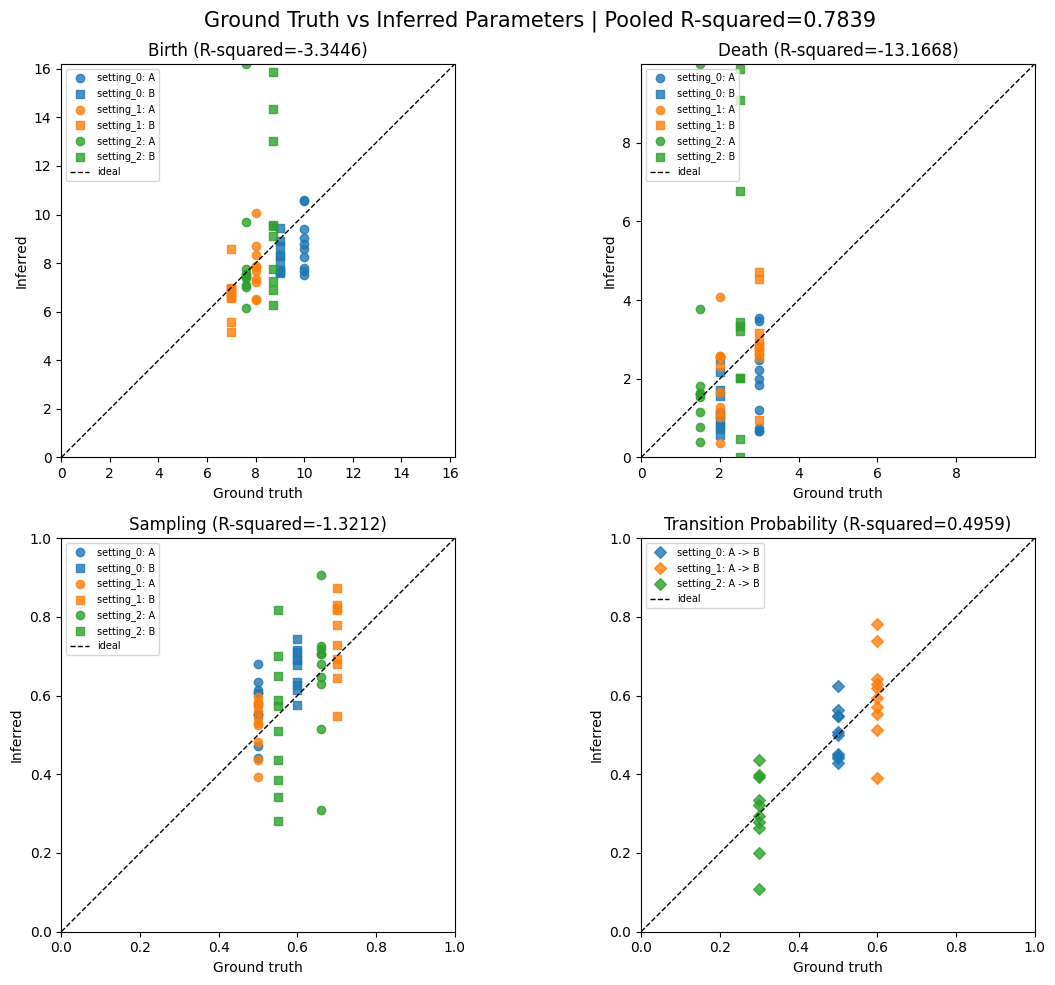

In [18]:
if comparison.empty:
    display(Markdown('No parameter plots yet. They will appear when inference outputs are ready.'))
else:
    setting_order = sorted(
        plot_comparison['setting'].unique(),
        key=lambda name: int(name.removeprefix('setting_')),
    )
    colors = plt.get_cmap('tab10')
    setting_colors = {
        setting: colors(index % 10) for index, setting in enumerate(setting_order)
    }
    marker_by_parameter = {'A': 'o', 'B': 's', 'A -> B': 'D'}

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))
    axes = axes.ravel()

    for axis, family in zip(axes, plot_families):
        subset = plot_comparison[plot_comparison['family'] == family]
        for (setting, parameter), points in subset.groupby(
            ['setting', 'parameter'], sort=False
        ):
            axis.scatter(
                points['truth'], points['inferred'],
                label=f'{setting}: {parameter}',
                color=setting_colors[setting],
                marker=marker_by_parameter.get(parameter, 'o'),
                alpha=0.8,
            )
        if family in ('sampling', 'transition probability'):
            high = 1.0
        else:
            high = max(float(subset['truth'].max()), float(subset['inferred'].max()), 0.01)
        axis.plot([0, high], [0, high], linestyle='--', color='black', linewidth=1, label='ideal')
        axis.set_xlim(0, high)
        axis.set_ylim(0, high)
        axis.set_aspect('equal', adjustable='box')
        axis.set_xlabel('Ground truth')
        axis.set_ylabel('Inferred')
        metric = r_squared(subset)
        if np.isnan(metric):
            mae = np.mean(np.abs(subset['truth'] - subset['inferred']))
            title = f'{family.title()} (R-squared undefined; MAE={mae:.4g})'
        else:
            title = f'{family.title()} (R-squared={metric:.4f})'
        axis.set_title(title)
        axis.legend(fontsize=7)

    fig.suptitle(
        f'Ground Truth vs Inferred Parameters | Pooled R-squared={plot_r2_text}',
        fontsize=15,
    )
    fig.tight_layout()
    plt.show()